In [1]:
path = "../data/nytcrosswords.csv"

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(path, encoding="latin-1")

In [3]:
df.columns

Index(['Date', 'Word', 'Clue'], dtype='str')

In [4]:
df['Date'] = pd.to_datetime(df['Date'])

In [5]:
df['Weekday'] = df['Date'].dt.day_name()

## This dataset contains entries all the way from 1993. I have doubts that the editor may not have fully maintained his pattern of ascending difficulties (Monday-easiest, Saturday-hardest). In order to verify this, I group the clue string length averages for every 5 years and ensure that the pattern is upheld over time.

In [6]:
df['ClueLength'] = df['Clue'].str.len()
df['Year'] = df['Date'].dt.year

print(df['Date'].min(), df['Date'].max())  # sanity check the real range

# average clue length by weekday, bucketed by 5-year windows
df['YearBucket'] = (df['Year'] // 5) * 5
pivot = df.groupby(['YearBucket', 'Weekday'])['ClueLength'].mean().unstack()
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = pivot[weekday_order]
print(pivot)

1993-11-21 00:00:00 2021-10-31 00:00:00
Weekday        Monday    Tuesday  Wednesday   Thursday     Friday   Saturday  \
YearBucket                                                                     
1990        14.553571  14.904878  14.839268  14.842053  15.155727  15.330819   
1995        15.530855  15.494782  15.320034  15.513277  16.128476  16.091034   
2000        16.280721  15.999420  15.891350  16.481581  17.159844  17.378303   
2005        17.971797  17.774772  17.481215  18.389463  19.470354  19.891824   
2010        19.558464  19.536260  19.513040  19.685678  20.625266  20.767821   
2015        21.299235  21.068522  20.912505  20.735876  21.232446  21.871306   
2020        22.060222  22.252441  22.318464  21.919704  22.627584  22.712119   

Weekday        Sunday  
YearBucket             
1990        15.301350  
1995        15.971507  
2000        16.505807  
2005        17.820585  
2010        18.597712  
2015        19.947242  
2020        21.879735  


## I recognize that the length of a clue may not directly correlate to its difficulty. So I instead use it as supporting evidence. The main verification comes from an increase in the use of "?" within clues. The editor often uses "?" in clues that contain puns which is often the hardest clue variant.

In [7]:
df['HasQuestionMark'] = df['Clue'].str.contains(r'\?', regex=True)

weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']  # Sunday excluded below

# Signal 1: wordplay density by weekday, across 5-year buckets
qmark_pivot = (df[df['Weekday'] != 'Sunday']
               .groupby(['YearBucket','Weekday'])['HasQuestionMark']
               .mean().unstack()[weekday_order])
print(qmark_pivot)

Weekday       Monday   Tuesday  Wednesday  Thursday    Friday  Saturday
YearBucket                                                             
1990        0.014524  0.017317   0.016320  0.029287  0.023120  0.027661
1995        0.009179  0.014125   0.018873  0.025145  0.034334  0.048176
2000        0.016828  0.023361   0.032606  0.033820  0.049083  0.045328
2005        0.013736  0.020365   0.029512  0.038124  0.055061  0.055998
2010        0.013534  0.025339   0.029897  0.049577  0.072028  0.079631
2015        0.019338  0.030005   0.034520  0.054677  0.059990  0.070355
2020        0.021899  0.030899   0.040325  0.049630  0.055565  0.065621


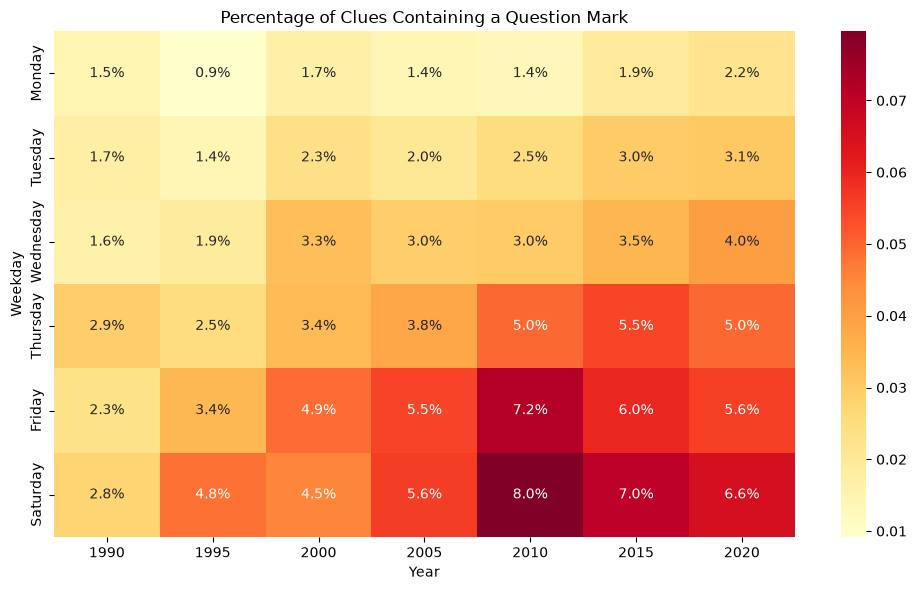

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(10, 6))

sns.heatmap(
    qmark_pivot.T,
    annot=True,
    fmt='.1%',
    cmap='YlOrRd'
)

plt.title('Percentage of Clues Containing a Question Mark')
plt.xlabel('Year')
plt.ylabel('Weekday')

plt.tight_layout()
plt.show()

### Upon further analysis, it appears that Shortz began strongly associating the use of "?" with an increase in difficulty over the years rather than from the start. Clues between 1990-2000 show weak signs of that pattern being upheld. If we assume "?" as the best indicator of clue difficulty then we should trim our dataset to timestamps where we can be certain that the difficulty increase pattern is upheld.

### I decide to trim my dataset to entries between 2003-2020.

In [9]:
sharpened_df = df[df['Date'].dt.year >= 2003].copy()
sharpened_df = sharpened_df[['Weekday', 'Clue', 'Word']]
sharpened_df = sharpened_df[sharpened_df['Weekday'] != 'Sunday']
sharpened_df

,Weekday,Clue,Word
130,Saturday,"Words on some flashcards, informally",VOCAB
131,Saturday,Stuff,SATE
132,Saturday,"""___ are ...""",ODDS
133,Saturday,"Academia, it's said",IVORYTOWER
134,Saturday,TV host who was the subject of the documentary...,NOAH
...,...,...,...
526223,Wednesday,Conductor Koussevitzky,SERGE
526224,Wednesday,It may be hard or soft,SELL
526225,Wednesday,Vein find,ORE
526226,Wednesday,Resistance unit,OHM


### Upon further data cleaning, I found nearly 120k duplicate pairs of clues and answers. If these pairs had slipped into the train and test split, then the model would have memorized the answers and displayed an inflated accuracy rate.

In [10]:
dupes = sharpened_df.duplicated(subset=['Clue', 'Word']).sum()
print(f"{dupes} exact duplicate clue/answer pairs out of {len(sharpened_df)}")

78562 exact duplicate clue/answer pairs out of 401023


In [11]:
sharpened_df = sharpened_df.drop_duplicates(subset=['Clue', 'Word'])

In [12]:
sharpened_df[sharpened_df['Weekday'] == 'Saturday'].head(25)

,Weekday,Clue,Word
130,Saturday,"Words on some flashcards, informally",VOCAB
131,Saturday,Stuff,SATE
132,Saturday,"""___ are ...""",ODDS
133,Saturday,"Academia, it's said",IVORYTOWER
134,Saturday,TV host who was the subject of the documentary...,NOAH
135,Saturday,Pot price,ANTE
136,Saturday,Its larva is eaten as a delicacy in the Mexica...,ANT
137,Saturday,Suffix with carboxyl,ASE
138,Saturday,"Loved, on social media",HEARTED
139,Saturday,"""Olympus ___ Fallen"" (2013 film)",HAS


In [13]:
sharpened_df[sharpened_df['Weekday'] == 'Monday'].tail(25)

,Weekday,Clue,Word
525789,Monday,"Patronized, as a restaurant",ATEAT
525792,Monday,Tiny poker stake,PENNY
525793,Monday,Having an angle,BENT
525798,Monday,True's partner,TRIED
525800,Monday,Rock's ___ John,ELTON
525801,Monday,Stadium sound,RAH
525802,Monday,Watch closely,EYE
525803,Monday,Blouse accompanier,SKIRT
525804,Monday,"Show, as plans",UNVEIL
525806,Monday,Tamed,GENTLE


## I'm currently considering what to use as features. I'm comparing the random clues above (from Monday and Saturday) to search for patterns. I'll test for correlation later but some contenders are: Num of Words, Question Mark Rate, Fill in the blanks, Clue length, Sum of Non-alphanumeric chars (besides the previously mentioned)

##### First, I calculated the average number of words used in a Monday clue vs a Saturday clue. The results should that Saturday uses **less** words on average. This actually contradicted my hypothesis because I assumed Saturday clues would use more complex phrasing and therefore be longer. As a sanity check, I calculated the average clue length of both of the days and actually found that Saturday uses **more** characters. This means that Saturday clues must be using longer, more sophisticated words. To prove this, I calculate the length of the average word in both of the days below.

In [14]:
monday_avg_word_length = ((sharpened_df[sharpened_df['Weekday'] == 'Monday']['Clue'].str.len())
                           / (sharpened_df[sharpened_df['Weekday'] == 'Monday']['Clue'].str.count(' ')+1)).mean()
print("the length of the average word in a monday clue is: ", monday_avg_word_length)

saturday_avg_word_length = ((sharpened_df[sharpened_df['Weekday'] == 'Saturday']['Clue'].str.len())
                             / (sharpened_df[sharpened_df['Weekday'] == 'Saturday']['Clue'].str.count(' ')+1)).mean()
print("the length of the average word in a saturday clue is: ", saturday_avg_word_length)

the length of the average word in a monday clue is:  6.244285144588333
the length of the average word in a saturday clue is:  6.271000301834705


**The results agree with my statement that Saturday clues on average use more sophisticated words. However, the difference is slight enough (0.0267151572 chars) that it makes me wonder if the pattern is upheld throughout the entire week. Below, I create a graph of the length of the average word in each day to verify the value's candidacy as a feature:**

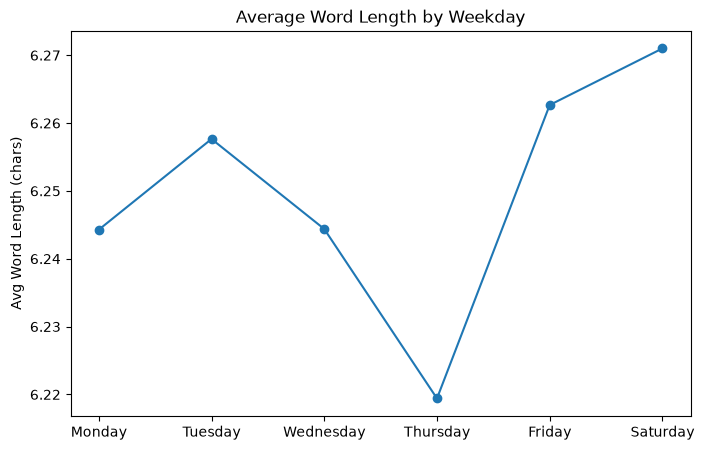

In [15]:
sharpened_df['Word Count'] = sharpened_df['Clue'].str.count(' ')+1
sharpened_df['Clue Length'] = sharpened_df['Clue'].str.len()
sharpened_df['Avg Word Length'] = sharpened_df['Clue Length'] / sharpened_df['Word Count']

weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']
avg_by_day = sharpened_df.groupby('Weekday')['Avg Word Length'].mean().reindex(weekday_order)

plt.figure(figsize=(8,5))
plt.plot(avg_by_day.index, avg_by_day.values, marker='o')
plt.title('Average Word Length by Weekday')
plt.ylabel('Avg Word Length (chars)')
plt.show()

**Although there isn't an obvious growth trend, at least the graph isn't a flat straight line. Each weekday has it's own unique avg word length with the exception of monday and thursday. The final model will likely be able to differentiate the two weekdays once I incorporate new features (provided that Monday and Thursday don't share an abnormal number of similarities in features). The overall signal is weak as the difference between the max and min is only about 0.05 chars, however, keeping this feature won't necessarily harm the model. Instead, it might show more value if paired with a fitting feature afterwards. I will be sure to test the final model with and without this feature in the training data.**

**I will now test correlation in fill in the blanks occurences**

In [16]:
from scipy.stats import chi2_contingency

sharpened_df['Has Fill Blank'] = sharpened_df['Clue'].str.contains('_')
contingency_table = pd.crosstab(sharpened_df['Weekday'], sharpened_df['Has Fill Blank'])
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("chi2 statistic:", chi2)
print("p-value:", p)

n = contingency_table.sum().sum()
r, c = contingency_table.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, c) - 1)))
print("Cramér's V:", cramers_v)

chi2 statistic: 514.4353310683254
p-value: 6.111282725244518e-109
Cramér's V: 0.039941723027144466


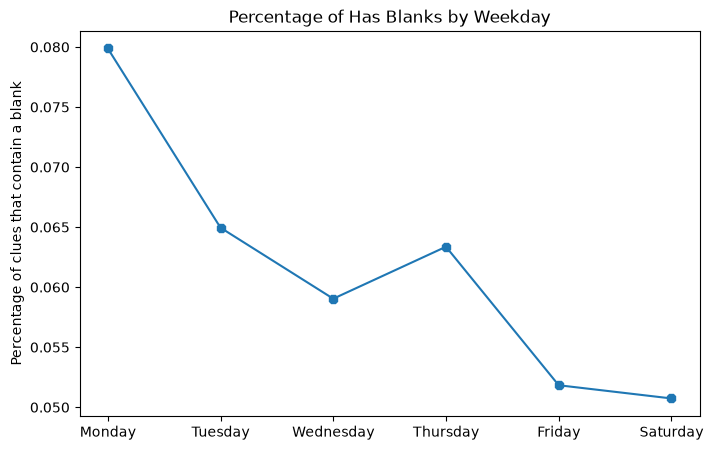

In [17]:
blank_rate_by_day = sharpened_df.groupby('Weekday')['Has Fill Blank'].mean().reindex(weekday_order)

plt.figure(figsize=(8, 5))
plt.plot(blank_rate_by_day.index, blank_rate_by_day.values, marker='8')
plt.title('Percentage of Has Blanks by Weekday')
plt.ylabel('Percentage of clues that contain a blank')
plt.show()

This looks to be another weakly contributing feature due to the weak result from calculating cramer's V (0.04). However, the downtrend is very apparent, and it appears that Thursday has distinguished itself from the other weekdays by breaking out of the trend again. There must be more to Thursday. Perhaps the author adds a special rule to Thursday clues. If this pattern keeps up in subsequent features, I'll investigate the cause of this discrepancy.

**Next, let's investigate the correlation of question mark use.**

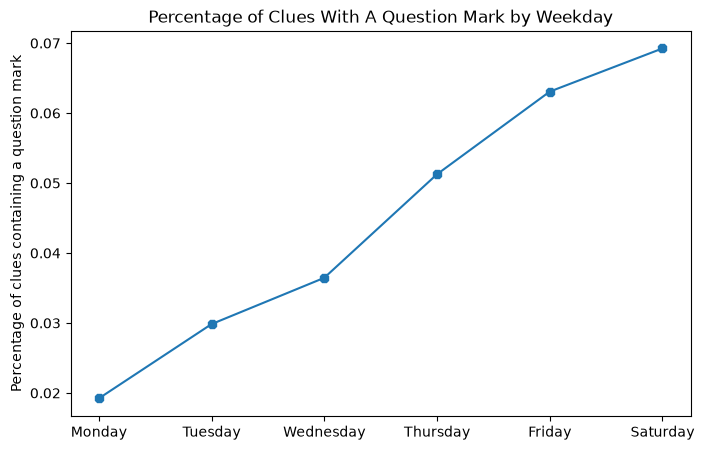

In [18]:
sharpened_df['Has Question Mark'] = sharpened_df['Clue'].str.contains('?', regex=False)

avg_has_question_by_day = sharpened_df.groupby('Weekday')['Has Question Mark'].mean().reindex(weekday_order)

plt.figure(figsize=(8, 5))
plt.plot(avg_has_question_by_day.index, avg_has_question_by_day.values, marker='8')
plt.title("Percentage of Clues With A Question Mark by Weekday")
plt.ylabel("Percentage of clues containing a question mark")
plt.show()

In [19]:
contingency_table = pd.crosstab(sharpened_df['Weekday'], sharpened_df['Has Question Mark'])

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("the p statistic: ", p)

n = contingency_table.sum().sum()
r, c = contingency_table.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, c) - 1)))
print("Cramér's V:", cramers_v)

the p statistic:  0.0
Cramér's V: 0.08551755698864605


This is by far the strongest feature so far. The graph resembles the most monotonic growth trend we've seen yet. However, the Cramer's V value is still less than 0.1.

If the most promising feature is this weak of a signal, then I'm worried about the model's capability to accurately make predictions. At this point, I'm reconsidering whether I should include the crossword **answer** as another branch of features. I am hoping it doesn't come to that because it will kill the simplicity in the demo phase which I'm aiming to maintain. This might be a hint that my chosen category of features (surface structure) might not be sufficient enough to make reliable predictions.

I'll instead use them as a supplement to my prediction and add a more complex feature:

    - checking the english popularity of the words used in the clue

In [20]:
sharpened_df['Weekday'] = pd.Categorical(sharpened_df['Weekday'], categories=weekday_order, ordered=True)
sharpened_df = sharpened_df.sort_values('Weekday')
sharpened_df = sharpened_df.drop(columns="Word Count")

Before I work on the complex feature, let's knock down the final feature in my initial set: Sum of Non-Alphanumeric Characters.

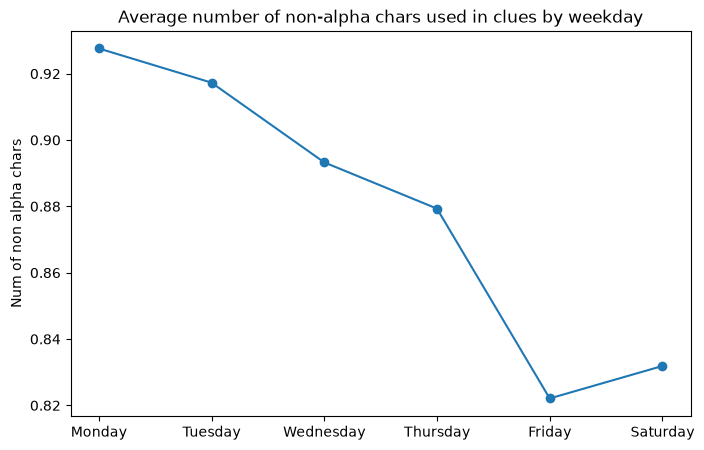

In [21]:
sharpened_df['Num of Non-Alpha Chars'] = sharpened_df['Clue'].str.count(r'[^_a-zA-Z0-9\s]')

avg_non_alpha_by_weekday = sharpened_df.groupby('Weekday')['Num of Non-Alpha Chars'].mean().reindex(weekday_order)

plt.figure(figsize=(8, 5))
plt.plot(avg_non_alpha_by_weekday.index, avg_non_alpha_by_weekday.values, marker = 'o')
plt.title("Average number of non-alpha chars used in clues by weekday")
plt.ylabel("Num of non alpha chars")
plt.show()

In [22]:
from scipy.stats import f_oneway

groups = [sharpened_df[sharpened_df['Weekday'] == day]['Num of Non-Alpha Chars'] for day in weekday_order]
f_stat, p = f_oneway(*groups)
print("F statistic:", f_stat)
print("p-value:", p)

grand_mean = sharpened_df['Num of Non-Alpha Chars'].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
ss_total = ((sharpened_df['Num of Non-Alpha Chars'] - grand_mean)**2).sum()
eta_squared = ss_between / ss_total
print("Eta-squared:", eta_squared)

F statistic: 55.18644245659167
p-value: 1.5771998426513424e-57
Eta-squared: 0.0008549915261963602


This feature's signal is neglible. I'm crossing it out as a candidate feature altogether. First, I'm going to build a model with the 4 surface structure features I've already tested. If the accuracy is below 60% then I'll add the new candidate feature.

In [23]:
sharpened_df = sharpened_df.drop(columns='Num of Non-Alpha Chars')
sharpened_df = sharpened_df.dropna()

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

def find_best_model(X, y, cv=5):
    models = {
        "Dummy": {
            'model': DummyClassifier(strategy='most_frequent'),
            'parameters': {}
        },
        "Logistic Regression": {
            'model': LogisticRegression(max_iter=1000),
            'parameters': {
                'C': [0.01, 0.1, 1, 10]
            }
        },
        "Random Forest": {
            'model': RandomForestClassifier(),
            'parameters': {
                'n_estimators': [100, 200],
                'max_depth': [None, 10, 20]
            }
        }
    }

    scores = []
    for model_name, model_params in models.items():
        gs = GridSearchCV(model_params['model'], model_params['parameters'], cv=cv, return_train_score=False)
        gs.fit(X, y)
        scores.append({
            'model': model_name,
            'best_parameters': gs.best_params_,
            'score': gs.best_score_
        })

    return pd.DataFrame(scores, columns=['model', 'best_parameters', 'score'])

features = ['Clue Length', 'Avg Word Length', 'Has Fill Blank', 'Has Question Mark']
target = 'Weekday'

X = sharpened_df[features]
y = sharpened_df[target]
find_best_model(X, y)

,model,best_parameters,score
0,Dummy,{},0.173836
1,Logistic Regression,{'C': 10},0.178231
2,Random Forest,"{'max_depth': 10, 'n_estimators': 100}",0.191926


In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier

best_model = RandomForestClassifier(max_depth=10, n_estimators=100)
y_pred = cross_val_predict(best_model, X, y, cv=5)

# map weekday names to their position in the week (0=Monday ... 5=Saturday)
day_to_num = {day: i for i, day in enumerate(weekday_order)}

y_true_num = y.map(day_to_num).astype(int)
y_pred_num = pd.Series(y_pred).map(day_to_num).astype(int)

diff = (y_true_num.values - y_pred_num.values)
wrong_mask = diff != 0
off_by_one = (abs(diff[wrong_mask]) == 1).mean()

print(f"Of the wrong predictions, {off_by_one:.1%} were off by exactly one weekday")

Of the wrong predictions, 36.5% were off by exactly one weekday


In [27]:
results_df = pd.DataFrame({'true': y_true_num, 'pred': y_pred_num})
results_df['diff'] = results_df['true'] - results_df['pred']
wrong = results_df[results_df['diff'] != 0]

off_by_one_by_day = wrong.groupby('true').apply(lambda g: (g['diff'].abs() == 1).mean())
off_by_one_by_day.index = off_by_one_by_day.index.map({v: k for k, v in day_to_num.items()})
print(off_by_one_by_day.reindex(weekday_order))

true
Monday       0.051096
Tuesday      0.423410
Wednesday    0.164491
Thursday     0.347119
Friday       0.180127
Saturday     0.042281
dtype: float64


In [24]:
import sys
sys.path.append('..')
from src.features import avg_word_frequency, min_word_frequency, answer_frequency

sharpened_df['Avg Word Freq'] = sharpened_df['Clue'].apply(avg_word_frequency)
sharpened_df['Min Word Freq'] = sharpened_df['Clue'].apply(min_word_frequency)
sharpened_df['Answer Freq'] = sharpened_df['Word'].apply(answer_frequency)
sharpened_df = sharpened_df.dropna()

In [25]:
sharpened_df

,Weekday,Clue,Word,Clue Length,Avg Word Length,Has Fill Blank,Has Question Mark,Avg Word Freq,Min Word Freq,Answer Freq
167330,Monday,Eastwood of Hollywood,CLINT,21,7.000000,False,False,5.070000,3.29,3.53
243892,Monday,Republican politico ___ Paul,RON,28,7.000000,True,False,4.296667,3.16,4.22
243890,Monday,"2, 3 or 4, usually, in miniature golf",PAR,37,4.625000,False,False,5.448000,3.72,4.15
243889,Monday,Gem weight unit,CARAT,15,5.000000,False,False,4.613333,3.87,3.15
243886,Monday,One of only two presidents with two Ivy League...,OBAMA,54,5.400000,False,False,5.662000,3.83,4.86
...,...,...,...,...,...,...,...,...,...,...
202374,Saturday,She came to Theseus' aid,ARIADNE,24,4.800000,False,False,5.334000,2.73,2.58
202373,Saturday,"""This is yours""",HERE,15,5.000000,False,False,6.213333,4.75,5.97
202372,Saturday,Stick selection,GEAR,15,7.500000,False,False,4.690000,4.62,4.46
202370,Saturday,They're not forbidding,OKS,22,7.333333,False,False,5.076667,3.07,2.22


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

numeric = ['Clue Length', 'Avg Word Length', 'Has Fill Blank', 'Has Question Mark',
           'Avg Word Freq', 'Min Word Freq']
X = sharpened_df[['Clue'] + numeric]
y = sharpened_df['Weekday']

# Easy / Medium / Hard version; comment this line out to predict the exact weekday
y = y.map({'Monday': 'Easy', 'Tuesday': 'Easy', 'Wednesday': 'Medium',
           'Thursday': 'Medium', 'Friday': 'Hard', 'Saturday': 'Hard'}).astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

preprocess = ColumnTransformer([t
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), 'Clue'),
    ('num', StandardScaler(), numeric),
])
pipe = Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=2000, C=0.3))])

pipe.fit(X_train, y_train)
print("Test accuracy:", pipe.score(X_test, y_test))
print("Baseline:", y_test.value_counts(normalize=True).max())

Test accuracy: 0.42207429475840236
Baseline: 0.3442727244514788
